In [1]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Coordenadas
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)

X, Y = np.meshgrid(x, y)

def gaussian_bivariate(X, Y, rho):

    covariance = np.array([
        [1, rho],
        [rho, 1]
    ])

    det = np.linalg.det(covariance)
    inv = np.linalg.inv(covariance)

    exponent = -0.5 * (
        inv[0, 0] * X**2
        + 2 * inv[0, 1] * X * Y
        + inv[1, 1] * Y**2
    )

    return np.exp(exponent) / (2 * np.pi * np.sqrt(det))


rhos = [-0.9, 0, 0.9]

fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "surface"}] * 3],
    subplot_titles=[
        "Negative correlation",
        "No correlation",
        "Positive correlation"
    ]
)

for i, rho in enumerate(rhos):

    Z = gaussian_bivariate(X, Y, rho)

    fig.add_trace(
        go.Surface(
            x=X,
            y=Y,
            z=Z,
            colorscale="Viridis",
            showscale=False,
            cmin=0,
            cmax=0.4
        ),
        row=1,
        col=i + 1
    )

fig.update_layout(
    title="Bivariate Gaussian Distribution",
    width=1400,
    height=550,
    margin=dict(l=0, r=0, b=0, t=80)
)

for i in range(1, 4):
    fig.update_layout(**{
        f"scene{i}": dict(
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Probability density",
            zaxis=dict(range=[0, 0.4]),
            aspectmode="cube"
        )
    })

fig.show()

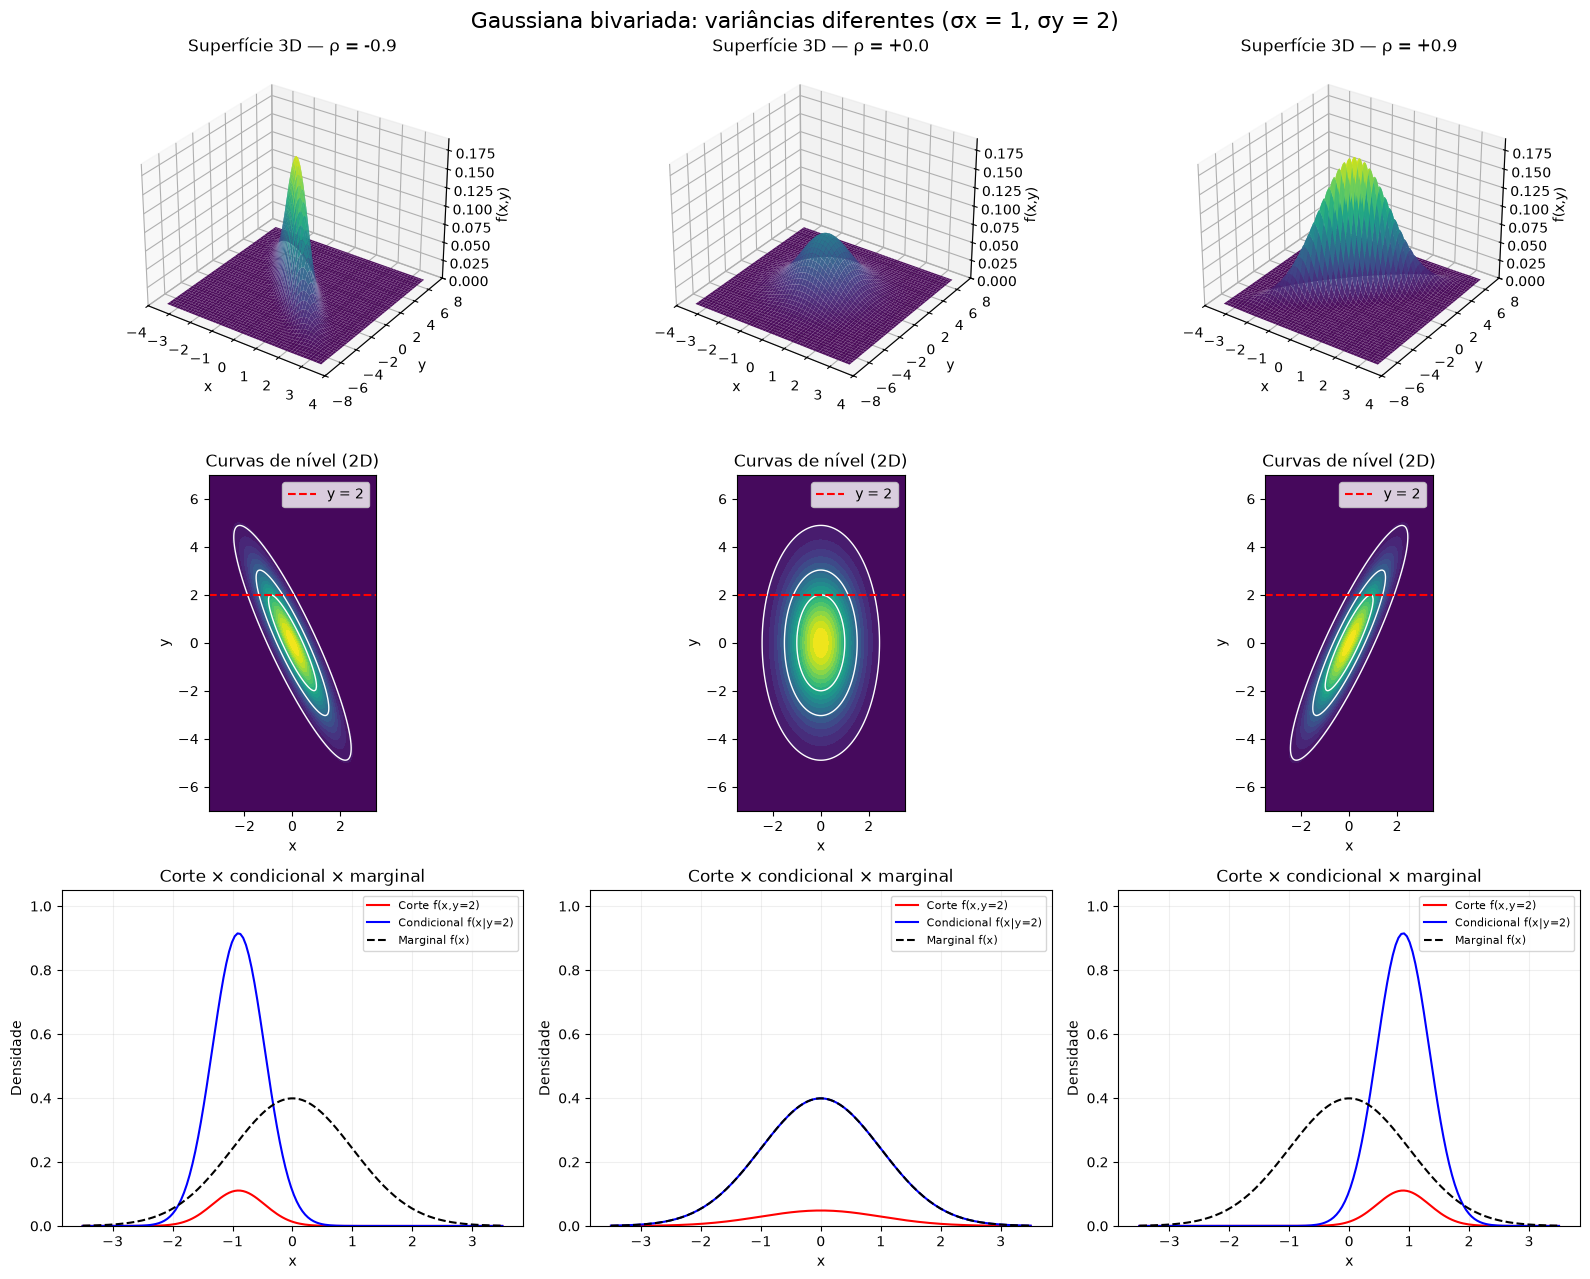

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Desvios-padrão diferentes
sigma_x = 1.0
sigma_y = 2.0

rhos = [-0.9, 0.0, 0.9]

x = np.linspace(-3.5, 3.5, 150)
y = np.linspace(-7, 7, 150)

X, Y = np.meshgrid(x, y)


def gaussian_bivariate(X, Y, rho):
    det = sigma_x**2 * sigma_y**2 * (1 - rho**2)

    q = (
        (X / sigma_x)**2
        - 2 * rho * X * Y / (sigma_x * sigma_y)
        + (Y / sigma_y)**2
    ) / (1 - rho**2)

    return np.exp(-q / 2) / (2 * np.pi * np.sqrt(det))


fig = plt.figure(figsize=(16, 13))

for i, rho in enumerate(rhos):

    Z = gaussian_bivariate(X, Y, rho)

    # 1ª linha: superfície 3D
    ax = fig.add_subplot(3, 3, i + 1, projection="3d")

    ax.plot_surface(
        X, Y, Z,
        cmap="viridis",
        vmin=0,
        vmax=0.19,
        linewidth=0,
        alpha=0.95
    )

    ax.set_title(f"Superfície 3D — ρ = {rho:+.1f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("f(x,y)")
    ax.set_zlim(0, 0.19)

    ax.view_init(elev=30, azim=-55)

    # 2ª linha: curvas de nível
    ax = fig.add_subplot(3, 3, i + 4)

    ax.contourf(
        X, Y, Z,
        levels=25,
        cmap="viridis"
    )

    # Contornos com mesma distância de Mahalanobis
    q = (
        (X / sigma_x)**2
        - 2 * rho * X * Y / (sigma_x * sigma_y)
        + (Y / sigma_y)**2
    ) / (1 - rho**2)

    ax.contour(
        X, Y, q,
        levels=[1, 2.30, 5.99],
        colors="white",
        linewidths=1
    )

    ax.axhline(
        2,
        color="red",
        linestyle="--",
        label="y = 2"
    )

    ax.set_title("Curvas de nível (2D)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.legend()

    # 3ª linha: corte, condicional e marginal
    ax = fig.add_subplot(3, 3, i + 7)

    y0 = 2.0

    marginal = norm.pdf(x, 0, sigma_x)

    conditional_mean = rho * sigma_x / sigma_y * y0

    conditional_std = sigma_x * np.sqrt(1 - rho**2)

    conditional = norm.pdf(
        x,
        conditional_mean,
        conditional_std
    )

    cut = conditional * norm.pdf(y0, 0, sigma_y)

    ax.plot(
        x, cut,
        color="red",
        label="Corte f(x,y=2)"
    )

    ax.plot(
        x, conditional,
        color="blue",
        label="Condicional f(x|y=2)"
    )

    ax.plot(
        x, marginal,
        "k--",
        label="Marginal f(x)"
    )

    ax.set_title("Corte × condicional × marginal")
    ax.set_xlabel("x")
    ax.set_ylabel("Densidade")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Gaussiana bivariada: variâncias diferentes "
    "(σx = 1, σy = 2)",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [3]:
%pip install plotly nbformat

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Parâmetros
sigma_x = 1.0
sigma_y = 2.0

rhos = [-0.9, 0.0, 0.9]

# Espaço dos observáveis
x = np.linspace(-3.5, 3.5, 120)
y = np.linspace(-7, 7, 120)

X, Y = np.meshgrid(x, y)


def gaussian_bivariate(X, Y, rho, sigma_x, sigma_y):

    det = sigma_x**2 * sigma_y**2 * (1 - rho**2)

    q = (
        (X / sigma_x)**2
        - 2 * rho * X * Y / (sigma_x * sigma_y)
        + (Y / sigma_y)**2
    ) / (1 - rho**2)

    return np.exp(-q / 2) / (2 * np.pi * np.sqrt(det))


# Três gráficos 3D
fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "surface"}] * 3],
    subplot_titles=[
        "ρ = -0.9 (anticorrelação)",
        "ρ = 0 (sem correlação)",
        "ρ = +0.9 (correlação)"
    ]
)

for i, rho in enumerate(rhos):

    Z = gaussian_bivariate(
        X, Y, rho, sigma_x, sigma_y
    )

    fig.add_trace(
        go.Surface(
            x=X,
            y=Y,
            z=Z,
            colorscale="Viridis",
            cmin=0,
            cmax=0.19,
            showscale=False,
            opacity=0.95
        ),
        row=1,
        col=i + 1
    )

# Configuração visual
fig.update_layout(
    title=(
        "Gaussianas bivariadas — "
        "σx = 1, σy = 2"
    ),
    width=1500,
    height=600,
    margin=dict(l=0, r=0, b=0, t=90)
)

# Mesma escala nos três gráficos
for i in range(1, 4):

    fig.update_layout(
        **{
            f"scene{i}": dict(
                xaxis=dict(
                    title="X",
                    range=[-3.5, 3.5]
                ),
                yaxis=dict(
                    title="Y",
                    range=[-7, 7]
                ),
                zaxis=dict(
                    title="Densidade",
                    range=[0, 0.19]
                ),
                aspectmode="manual",
                aspectratio=dict(
                    x=1,
                    y=2,
                    z=0.8
                )
            )
        }
    )

fig.show()

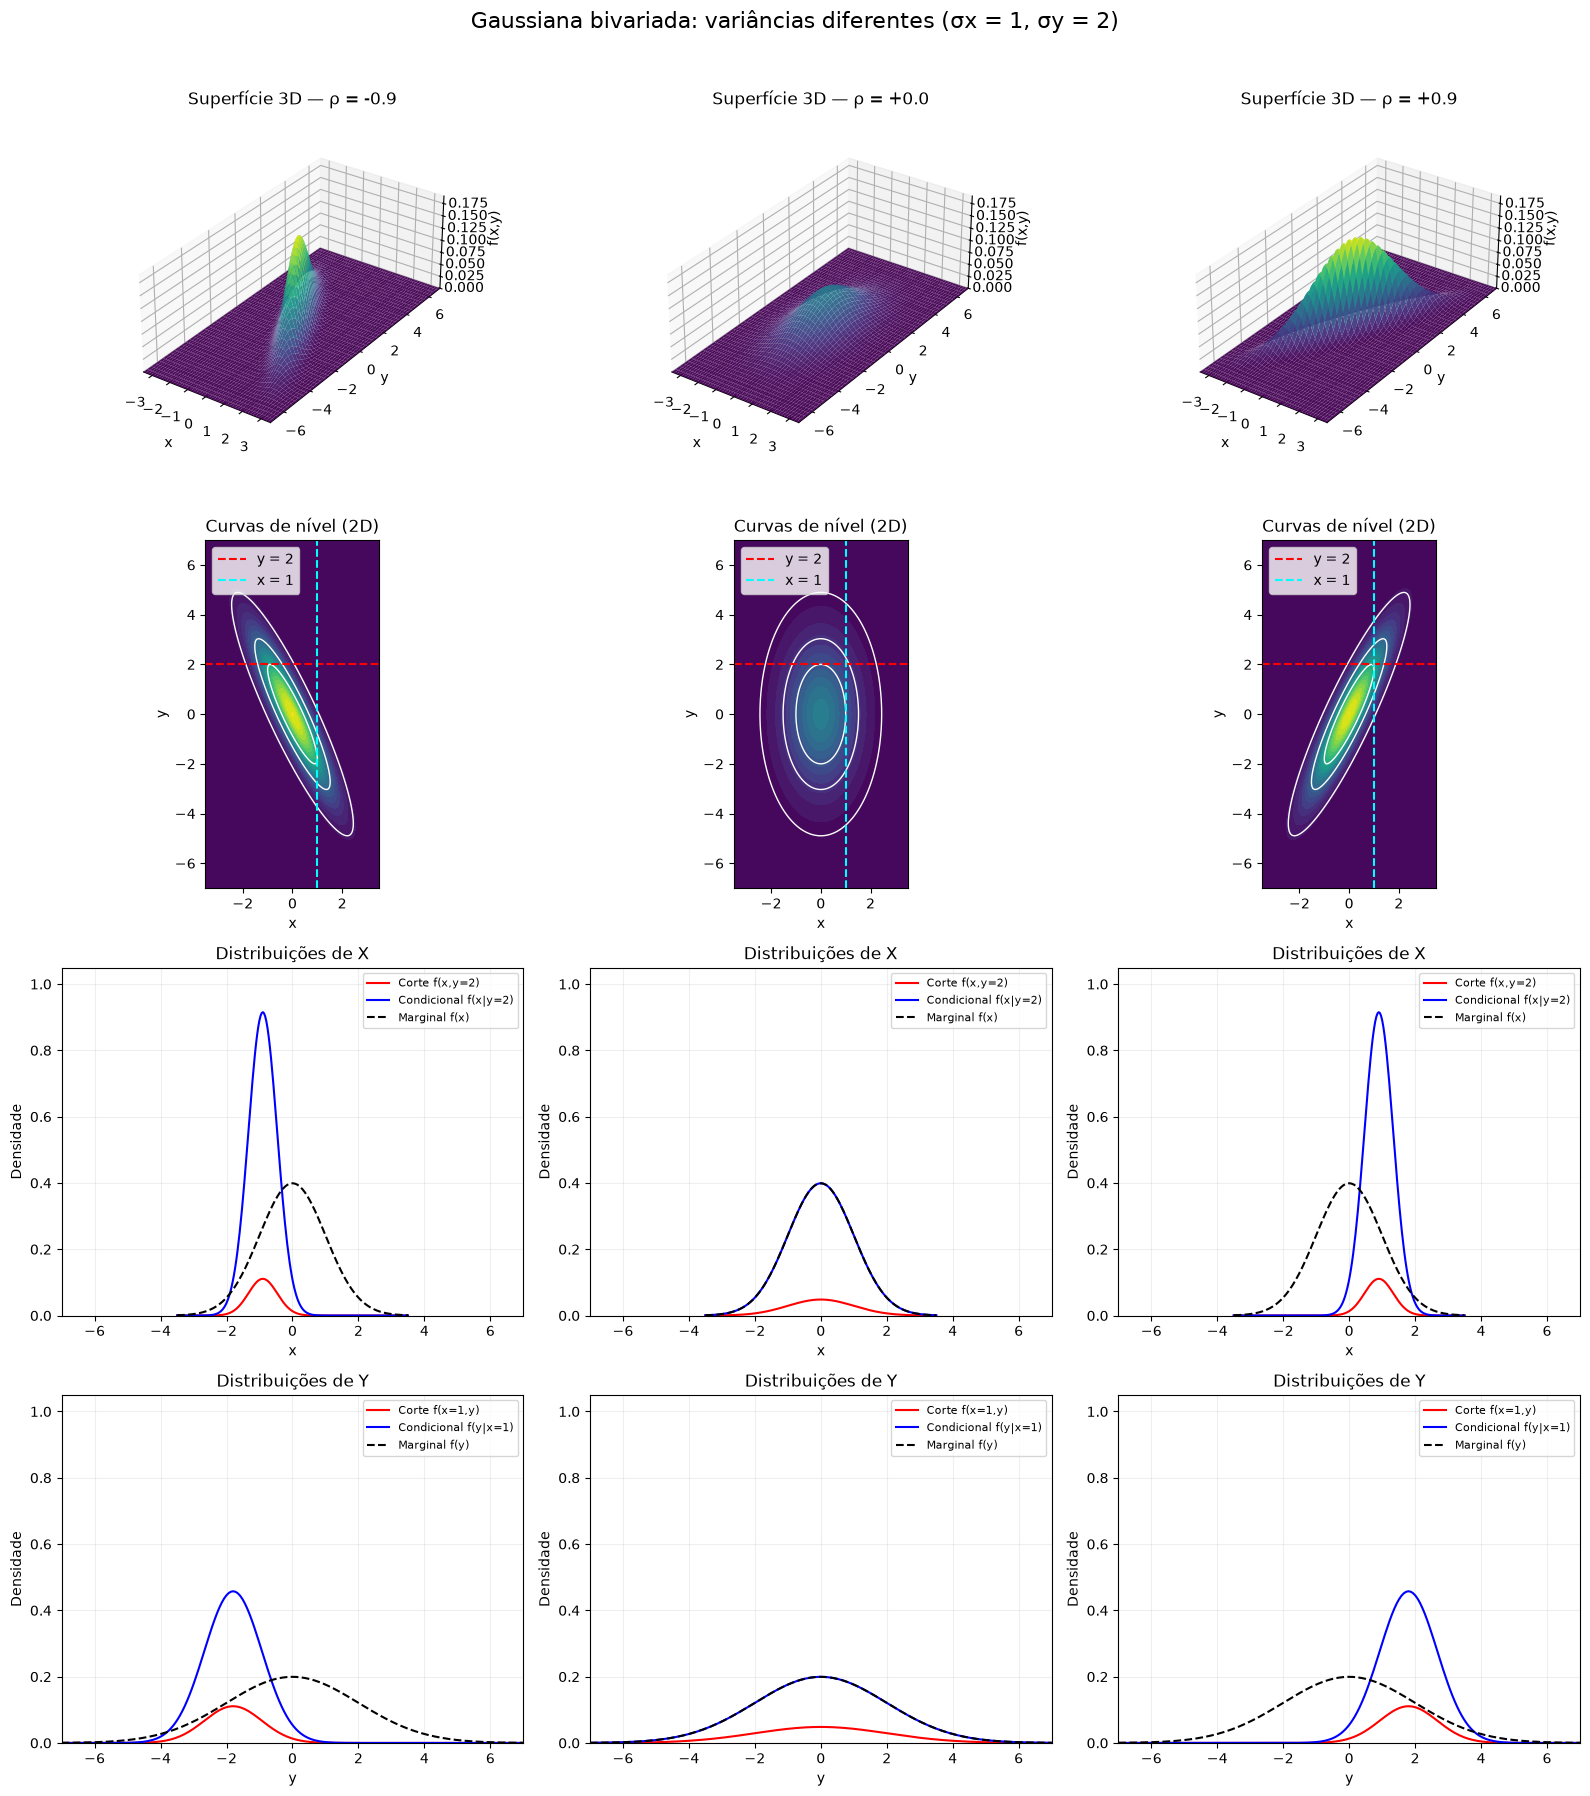

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ==========================================
# PARÂMETROS
# ==========================================

sigma_x = 1.0
sigma_y = 2.0

rhos = [-0.9, 0.0, 0.9]

# Domínio da distribuição conjunta
x = np.linspace(-3.5, 3.5, 200)
y = np.linspace(-7, 7, 200)

X, Y = np.meshgrid(x, y)

# Pontos dos cortes
x0 = 1.0
y0 = 2.0

# Escalas comuns para as distribuições 1D
density_xlim = (-7, 7)
density_ylim = (0, 1.05)

# Escala comum para a densidade conjunta
joint_density_max = 0.19


def gaussian_bivariate(X, Y, rho):
    det = sigma_x**2 * sigma_y**2 * (1 - rho**2)

    q = (
        (X / sigma_x)**2
        - 2 * rho * X * Y / (sigma_x * sigma_y)
        + (Y / sigma_y)**2
    ) / (1 - rho**2)

    return np.exp(-q / 2) / (2 * np.pi * np.sqrt(det))


# ==========================================
# FIGURA: 4 LINHAS × 3 COLUNAS
# ==========================================

fig = plt.figure(figsize=(16, 18))

for i, rho in enumerate(rhos):

    Z = gaussian_bivariate(X, Y, rho)

    # ==========================================
    # 1ª LINHA — SUPERFÍCIE 3D
    # ==========================================

    ax = fig.add_subplot(4, 3, i + 1, projection="3d")

    ax.plot_surface(
        X, Y, Z,
        cmap="viridis",
        vmin=0,
        vmax=joint_density_max,
        linewidth=0,
        alpha=0.95
    )

    ax.set_title(f"Superfície 3D — ρ = {rho:+.1f}")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("f(x,y)")

    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-7, 7)
    ax.set_zlim(0, joint_density_max)

    ax.set_box_aspect((7, 14, 5))

    ax.view_init(elev=30, azim=-55)

    # ==========================================
    # 2ª LINHA — CURVAS DE NÍVEL
    # ==========================================

    ax = fig.add_subplot(4, 3, i + 4)

    ax.contourf(
        X, Y, Z,
        levels=np.linspace(0, joint_density_max, 26),
        cmap="viridis",
        vmin=0,
        vmax=joint_density_max
    )

    # Distância de Mahalanobis
    q = (
        (X / sigma_x)**2
        - 2 * rho * X * Y / (sigma_x * sigma_y)
        + (Y / sigma_y)**2
    ) / (1 - rho**2)

    ax.contour(
        X, Y, q,
        levels=[1, 2.30, 5.99],
        colors="white",
        linewidths=1
    )

    # Corte horizontal: X condicionado a Y = 2
    ax.axhline(
        y0,
        color="red",
        linestyle="--",
        label=f"y = {y0:g}"
    )

    # Corte vertical: Y condicionado a X = 1
    ax.axvline(
        x0,
        color="cyan",
        linestyle="--",
        label=f"x = {x0:g}"
    )

    ax.set_title("Curvas de nível (2D)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-7, 7)

    ax.set_aspect("equal")
    ax.legend()

    # ==========================================
    # 3ª LINHA — DISTRIBUIÇÕES DE X
    # ==========================================

    ax = fig.add_subplot(4, 3, i + 7)

    # Marginal f(x)
    marginal_x = norm.pdf(
        x,
        loc=0,
        scale=sigma_x
    )

    # Condicional f(x | y = y0)
    conditional_mean_x = (
        rho * sigma_x / sigma_y * y0
    )

    conditional_std_x = (
        sigma_x * np.sqrt(1 - rho**2)
    )

    conditional_x = norm.pdf(
        x,
        loc=conditional_mean_x,
        scale=conditional_std_x
    )

    # Corte da densidade conjunta f(x, y0)
    cut_x = (
        conditional_x
        * norm.pdf(y0, loc=0, scale=sigma_y)
    )

    ax.plot(
        x,
        cut_x,
        color="red",
        label=f"Corte f(x,y={y0:g})"
    )

    ax.plot(
        x,
        conditional_x,
        color="blue",
        label=f"Condicional f(x|y={y0:g})"
    )

    ax.plot(
        x,
        marginal_x,
        "k--",
        label="Marginal f(x)"
    )

    ax.set_title("Distribuições de X")
    ax.set_xlabel("x")
    ax.set_ylabel("Densidade")

    # MESMAS ESCALAS PARA X E Y
    ax.set_xlim(*density_xlim)
    ax.set_ylim(*density_ylim)

    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

    # ==========================================
    # 4ª LINHA — DISTRIBUIÇÕES DE Y
    # ==========================================

    ax = fig.add_subplot(4, 3, i + 10)

    # Marginal f(y)
    marginal_y = norm.pdf(
        y,
        loc=0,
        scale=sigma_y
    )

    # Condicional f(y | x = x0)
    conditional_mean_y = (
        rho * sigma_y / sigma_x * x0
    )

    conditional_std_y = (
        sigma_y * np.sqrt(1 - rho**2)
    )

    conditional_y = norm.pdf(
        y,
        loc=conditional_mean_y,
        scale=conditional_std_y
    )

    # Corte da densidade conjunta f(x0, y)
    cut_y = (
        conditional_y
        * norm.pdf(x0, loc=0, scale=sigma_x)
    )

    ax.plot(
        y,
        cut_y,
        color="red",
        label=f"Corte f(x={x0:g},y)"
    )

    ax.plot(
        y,
        conditional_y,
        color="blue",
        label=f"Condicional f(y|x={x0:g})"
    )

    ax.plot(
        y,
        marginal_y,
        "k--",
        label="Marginal f(y)"
    )

    ax.set_title("Distribuições de Y")
    ax.set_xlabel("y")
    ax.set_ylabel("Densidade")

    # EXATAMENTE AS MESMAS ESCALAS DE X
    ax.set_xlim(*density_xlim)
    ax.set_ylim(*density_ylim)

    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)


# ==========================================
# FINALIZAÇÃO
# ==========================================

fig.suptitle(
    "Gaussiana bivariada: variâncias diferentes "
    "(σx = 1, σy = 2)",
    fontsize=16,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()